In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("XGBoost:", xgb.__version__)

Pandas: 2.3.2
NumPy: 2.2.6
XGBoost: 3.4.1


# Bước 7: Phân tích Feature Importance

## Mục tiêu
- Phân tích mức độ quan trọng của các Lag Features trong mô hình XGBoost.
- Xác định những biến đầu vào có ảnh hưởng lớn nhất đến kết quả dự đoán.
- Trực quan hóa Feature Importance bằng biểu đồ.

In [2]:
from pathlib import Path

# Xác định thư mục gốc của project
PROJECT_DIR = Path.cwd().parent

# Đường dẫn đến thư mục models và dữ liệu
MODEL_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "data" / "processed"

# Liệt kê file mô hình
print("Các file trong thư mục models:")
for file in MODEL_DIR.iterdir():
    print("-", file.name)

# Liệt kê file dữ liệu
print("\nCác file trong thư mục data/processed:")
for file in DATA_DIR.iterdir():
    print("-", file.name)

Các file trong thư mục models:
- xgboost_model.pkl

Các file trong thư mục data/processed:
- AEP_cleaned.csv
- X_lag_p24.csv
- X_test.csv
- X_train.csv
- y_AEP_MW.csv
- y_test.csv
- y_train.csv


## 1. Tải mô hình và dữ liệu kiểm tra

Sử dụng mô hình XGBoost đã được huấn luyện ở bước trước và tập dữ liệu X_test để phân tích mức độ quan trọng của các đặc trưng.

In [3]:
import joblib
import pandas as pd
from pathlib import Path

# Đường dẫn đến mô hình và dữ liệu
model_path = MODEL_DIR / "xgboost_model.pkl"
test_path = DATA_DIR / "X_test.csv"

# Tải mô hình đã huấn luyện
model = joblib.load(model_path)

# Tải dữ liệu kiểm tra
X_test = pd.read_csv(test_path)

# Hiển thị thông tin
print("Loại mô hình:", type(model))
print("Kích thước X_test:", X_test.shape)

print("\n5 dòng dữ liệu đầu tiên:")
display(X_test.head())

Loại mô hình: <class 'xgboost.sklearn.XGBRegressor'>
Kích thước X_test: (24249, 25)

5 dòng dữ liệu đầu tiên:


C:\Users\chong\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\pickle.py:1760: UserWarning: [02:34:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


,Datetime,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24
0,2015-10-27 13:00:00,14718.0,14796.0,15147.0,14837.0,14867.0,14032.0,12583.0,11779.0,11600.0,...,13984.0,14584.0,14737.0,14168.0,13717.0,13691.0,13788.0,13949.0,14077.0,14299.0
1,2015-10-27 14:00:00,14689.0,14718.0,14796.0,15147.0,14837.0,14867.0,14032.0,12583.0,11779.0,...,13216.0,13984.0,14584.0,14737.0,14168.0,13717.0,13691.0,13788.0,13949.0,14077.0
2,2015-10-27 15:00:00,14609.0,14689.0,14718.0,14796.0,15147.0,14837.0,14867.0,14032.0,12583.0,...,12511.0,13216.0,13984.0,14584.0,14737.0,14168.0,13717.0,13691.0,13788.0,13949.0
3,2015-10-27 16:00:00,14459.0,14609.0,14689.0,14718.0,14796.0,15147.0,14837.0,14867.0,14032.0,...,11894.0,12511.0,13216.0,13984.0,14584.0,14737.0,14168.0,13717.0,13691.0,13788.0
4,2015-10-27 17:00:00,14366.0,14459.0,14609.0,14689.0,14718.0,14796.0,15147.0,14837.0,14867.0,...,11699.0,11894.0,12511.0,13216.0,13984.0,14584.0,14737.0,14168.0,13717.0,13691.0


In [4]:
# Kiểm tra số lượng đặc trưng của mô hình
booster = model.get_booster()

print("Số lượng cây:", booster.num_boosted_rounds())
print("Số lượng đặc trưng:", booster.num_features())

print("\nTên các đặc trưng:")
print(X_test.columns.tolist())

Số lượng cây: 300
Số lượng đặc trưng: 24

Tên các đặc trưng:
['Datetime', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'lag_13', 'lag_14', 'lag_15', 'lag_16', 'lag_17', 'lag_18', 'lag_19', 'lag_20', 'lag_21', 'lag_22', 'lag_23', 'lag_24']


In [5]:
# Lấy tên đặc trưng mà mô hình thực sự sử dụng
model_features = booster.feature_names

print("Số đặc trưng trong mô hình:", booster.num_features())

print("\nTên đặc trưng trong mô hình:")
print(model_features)

print("\nSố cột trong X_test:", len(X_test.columns))

print("\nCác cột không thuộc mô hình:")
print(set(X_test.columns) - set(model_features) if model_features else "Mô hình không lưu tên đặc trưng")

Số đặc trưng trong mô hình: 24

Tên đặc trưng trong mô hình:
['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'lag_13', 'lag_14', 'lag_15', 'lag_16', 'lag_17', 'lag_18', 'lag_19', 'lag_20', 'lag_21', 'lag_22', 'lag_23', 'lag_24']

Số cột trong X_test: 25

Các cột không thuộc mô hình:
{'Datetime'}


In [7]:
# Lấy Feature Importance theo 3 phương pháp
importance_gain = booster.get_score(importance_type="gain")
importance_weight = booster.get_score(importance_type="weight")
importance_cover = booster.get_score(importance_type="cover")

# Tạo bảng gồm đầy đủ 24 Lag Features
importance_df = pd.DataFrame({
    "Feature": model_features
})

# Thêm các chỉ số
importance_df["Gain"] = importance_df["Feature"].map(importance_gain).fillna(0)
importance_df["Weight"] = importance_df["Feature"].map(importance_weight).fillna(0)
importance_df["Cover"] = importance_df["Feature"].map(importance_cover).fillna(0)

# Tính tỷ lệ Gain (%)
total_gain = importance_df["Gain"].sum()

importance_df["Gain_Percent"] = (
    importance_df["Gain"] / total_gain * 100
)

# Sắp xếp theo Gain giảm dần
importance_df = importance_df.sort_values(
    by="Gain", ascending=False
).reset_index(drop=True)

# Hiển thị Top 15
display(importance_df.head(15).round(4))

,Feature,Gain,Weight,Cover,Gain_Percent
0,lag_1,1.446261e+09,2617.0,15757.2031,57.0543
1,lag_2,6.038070e+08,1921.0,9424.3418,23.8199
2,lag_22,1.358005e+08,701.0,5664.4150,5.3573
3,lag_23,9.749778e+07,982.0,13264.7119,3.8462
4,lag_21,4.370995e+07,693.0,5014.6855,1.7243
5,lag_3,3.807125e+07,955.0,6019.3916,1.5019
6,lag_4,2.651646e+07,671.0,3879.4695,1.0461
7,lag_24,1.962880e+07,1531.0,15276.3955,0.7743
8,lag_10,1.818758e+07,738.0,3782.5015,0.7175
9,lag_5,1.481235e+07,552.0,2933.6450,0.5843


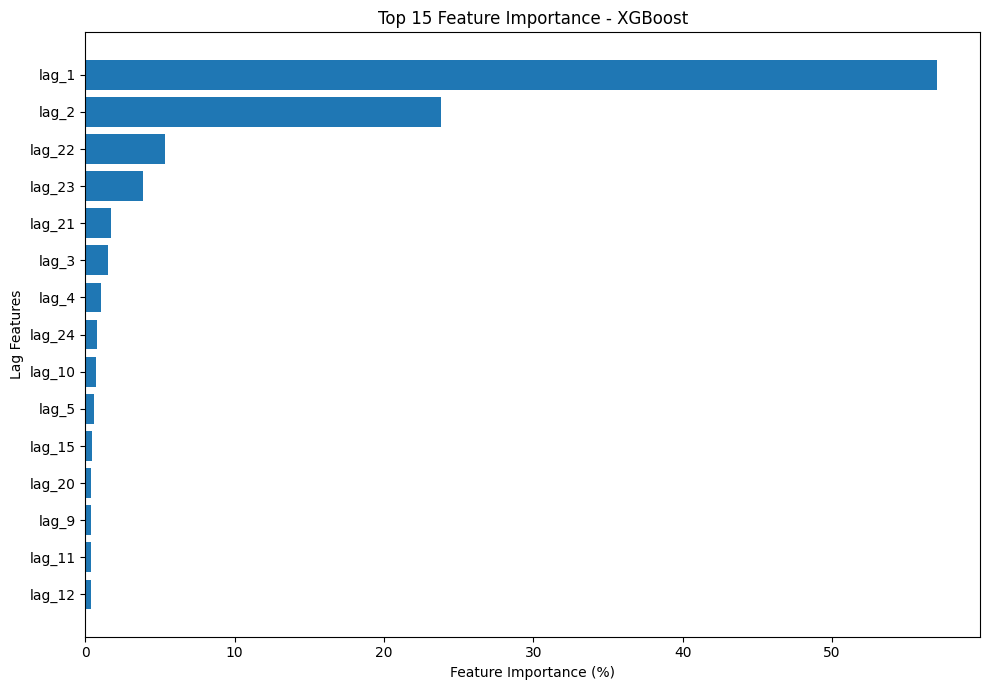

In [8]:
# Lấy Top 15 đặc trưng theo Gain
top_features = importance_df.head(15).sort_values(
    by="Gain_Percent"
)

# Vẽ biểu đồ
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Gain_Percent"]
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Lag Features")
plt.title("Top 15 Feature Importance - XGBoost")

plt.tight_layout()
plt.show()

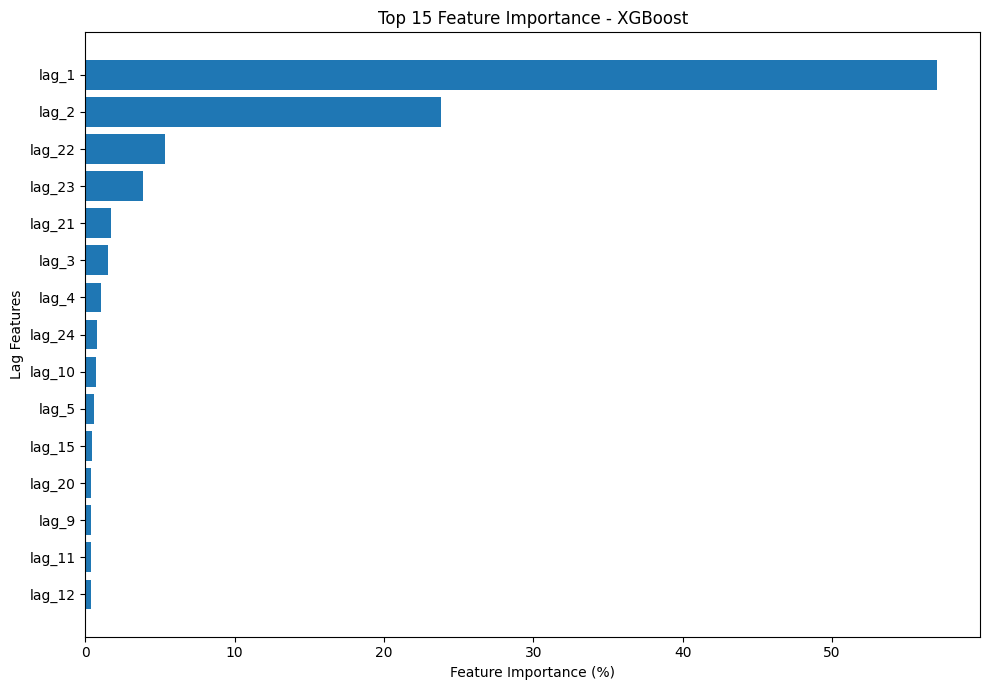

Đã lưu bảng và biểu đồ Feature Importance!


In [9]:
# Tạo thư mục lưu kết quả
output_dir = PROJECT_DIR / "reports" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

# Lưu bảng Feature Importance
importance_df.to_csv(
    PROJECT_DIR / "reports" / "feature_importance.csv",
    index=False
)

# Lưu biểu đồ
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Gain_Percent"]
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Lag Features")
plt.title("Top 15 Feature Importance - XGBoost")

plt.tight_layout()

plt.savefig(
    output_dir / "06_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu bảng và biểu đồ Feature Importance!")